# Customer Churn Prediction
Telecom companies lose revenue every time a customer cancels. The goal here is to **predict which customers are likely to churn** so a retention team can reach them first.

**Data:** IBM Telco Customer Churn — 7,043 customers, 19 features (contract, services, billing).  
**Metric:** ROC-AUC (ranking quality), plus recall/precision for the churn class.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import classification_report, roc_auc_score, ConfusionMatrixDisplay
from xgboost import XGBClassifier
sns.set_theme(style='whitegrid'); SEED = 42

## 1. Load and clean

In [2]:
df = pd.read_csv('https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv')
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print(df.shape)
print('Blank TotalCharges:', df['TotalCharges'].isna().sum(), '— all have tenure 0:',
      (df.loc[df['TotalCharges'].isna(), 'tenure'] == 0).all())
df['TotalCharges'] = df['TotalCharges'].fillna(0.0)   # new customers, nothing billed yet
df['SeniorCitizen'] = df['SeniorCitizen'].map({0: 'No', 1: 'Yes'})
df = df.drop(columns='customerID')
df.head()

(7043, 21)
Blank TotalCharges: 11 — all have tenure 0: True


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,No,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,No,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df['Churn'].value_counts(normalize=True).round(3)

Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64

About 27% of customers churn, so the classes are imbalanced — accuracy alone would be misleading.

## 2. Exploratory analysis

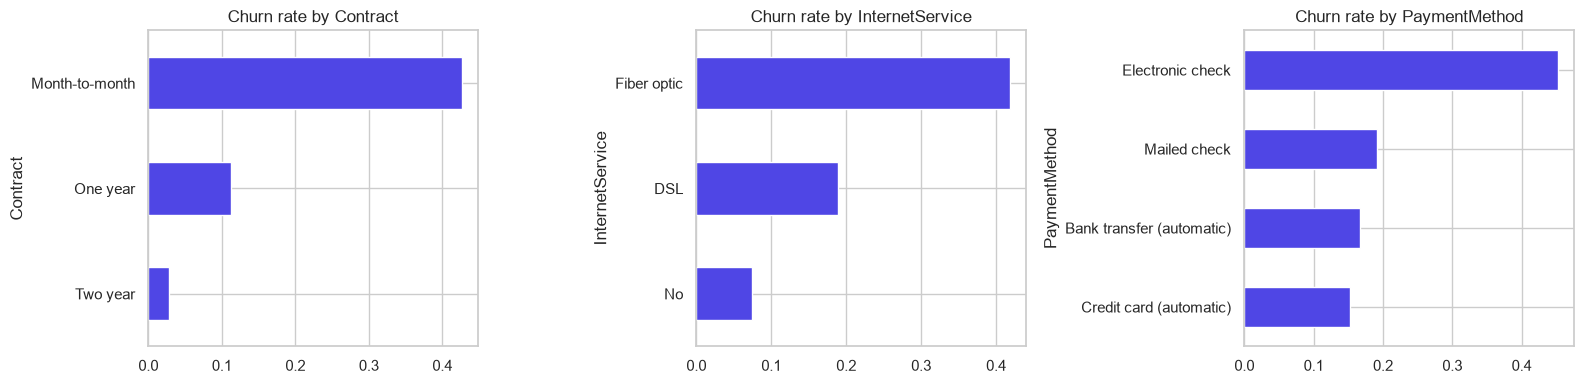

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ['Contract', 'InternetService', 'PaymentMethod']):
    (df.groupby(col)['Churn'].apply(lambda s: (s == 'Yes').mean())
       .sort_values().plot.barh(ax=ax, color='#4f46e5'))
    ax.set_title(f'Churn rate by {col}'); ax.set_xlabel('')
plt.tight_layout()

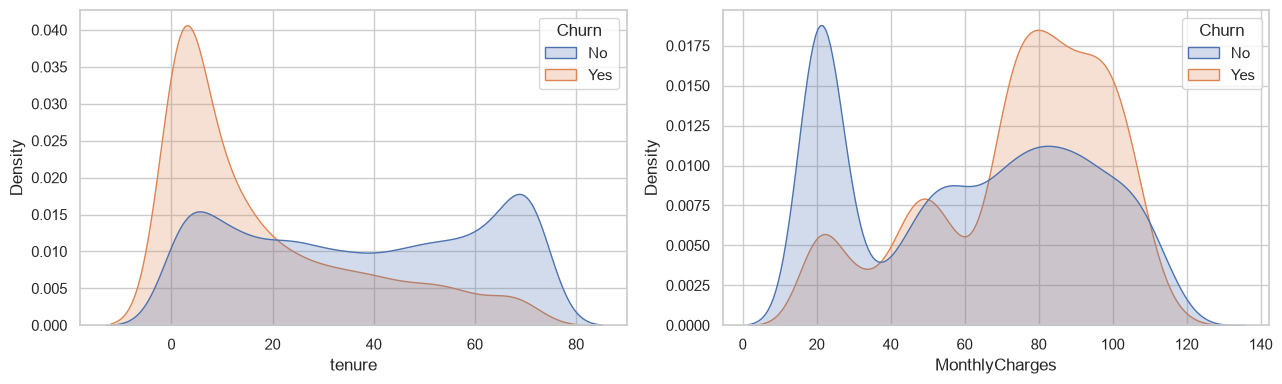

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.kdeplot(data=df, x='tenure', hue='Churn', common_norm=False, fill=True, ax=axes[0])
sns.kdeplot(data=df, x='MonthlyCharges', hue='Churn', common_norm=False, fill=True, ax=axes[1])
plt.tight_layout()

**Findings**
- Month-to-month contracts churn ~43% vs ~3% for two-year contracts.
- Fiber-optic users and electronic-check payers churn more.
- Churners are concentrated in the first months of tenure and pay higher monthly charges.

## 3. Modelling
One `Pipeline` handles preprocessing so there is no leakage between folds. Models are compared with 5-fold stratified cross-validation on the training set only.

In [6]:
X, y = df.drop(columns='Churn'), (df['Churn'] == 'Yes').astype(int)
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
cat_cols = [c for c in X.columns if c not in num_cols]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

prep = ColumnTransformer([('num', StandardScaler(), num_cols),
                          ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)])
models = {
    'Logistic Regression': LogisticRegression(max_iter=2000, C=0.5),
    'Random Forest': RandomForestClassifier(n_estimators=400, max_depth=8, min_samples_leaf=5, random_state=SEED, n_jobs=-1),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, max_depth=3, random_state=SEED),
    'XGBoost': XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8, random_state=SEED),
}
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
rows = []
for name, m in models.items():
    r = cross_validate(Pipeline([('prep', prep), ('model', m)]), X_train, y_train, cv=cv,
                       scoring=['roc_auc', 'f1', 'recall'], n_jobs=-1)
    rows.append({'model': name, **{k: r[f'test_{k}'].mean() for k in ['roc_auc', 'f1', 'recall']}})
pd.DataFrame(rows).sort_values('roc_auc', ascending=False).round(3)

,model,roc_auc,f1,recall
1,Random Forest,0.848,0.578,0.503
2,Gradient Boosting,0.848,0.586,0.528
0,Logistic Regression,0.846,0.594,0.544
3,XGBoost,0.844,0.586,0.527


Logistic Regression is as good as the tree ensembles here (the signal is mostly linear in one-hot features) and it is simpler and easier to explain, so it is the final model.

## 4. Final evaluation on the test set

ROC-AUC: 0.842
              precision    recall  f1-score   support

       Stays       0.85      0.89      0.87      1035
      Churns       0.65      0.55      0.60       374

    accuracy                           0.80      1409
   macro avg       0.75      0.72      0.73      1409
weighted avg       0.79      0.80      0.80      1409



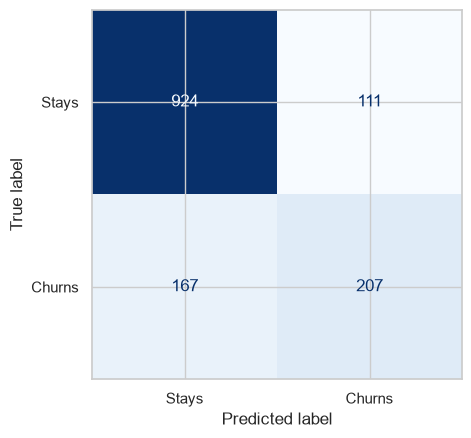

In [7]:
final = Pipeline([('prep', prep), ('model', LogisticRegression(max_iter=2000, C=0.5))]).fit(X_train, y_train)
proba = final.predict_proba(X_test)[:, 1]
print('ROC-AUC:', round(roc_auc_score(y_test, proba), 3))
print(classification_report(y_test, proba >= 0.5, target_names=['Stays', 'Churns']))
ConfusionMatrixDisplay.from_predictions(y_test, proba >= 0.5, display_labels=['Stays', 'Churns'], cmap='Blues', colorbar=False);

### Choosing a threshold
For retention, missing a churner costs more than an extra phone call, so a lower threshold trades precision for recall:

In [8]:
from sklearn.metrics import precision_score, recall_score
pd.DataFrame([{'threshold': t, 'precision': precision_score(y_test, proba >= t), 'recall': recall_score(y_test, proba >= t)}
              for t in [0.3, 0.4, 0.5, 0.6]]).round(3)

,threshold,precision,recall
0,0.3,0.521,0.754
1,0.4,0.572,0.671
2,0.5,0.651,0.553
3,0.6,0.716,0.404


### What drives churn

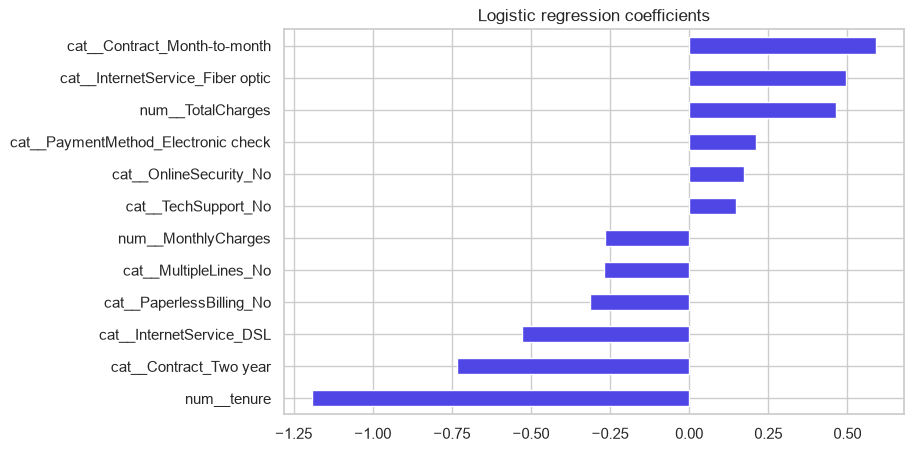

In [9]:
names = final.named_steps['prep'].get_feature_names_out()
coef = pd.Series(final.named_steps['model'].coef_[0], index=names).sort_values()
pd.concat([coef.head(6), coef.tail(6)]).plot.barh(figsize=(8, 5), color='#4f46e5', title='Logistic regression coefficients');

## 5. Conclusions
- The model ranks churners well (ROC-AUC ≈ 0.84) and catches most of them at a 0.3–0.4 threshold.
- Biggest levers: contract length, tenure, fiber internet, electronic check payments, missing tech support.
- Business idea: offer month-to-month fiber customers a discounted 1-year contract with tech support.

The production version of this pipeline is in `train.py`; it is exported to ONNX and runs in the web demo.